# Rețele neuronale și deep learning — Cursul 8: Modele generative: autoencodere, VAE, GAN, difuzie
Prof. dr. Daniel Traian Pele — Academia de Studii Economice din București (ASE); Academia Română, Institutul de Prognoză Economică (IPE)

[Deschide în Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/notebooks/L8_notebook_ro.ipynb)

Acest notebook reproduce cifrele și graficele cursului pe datele reale din `../data/clean` (vezi `../data/SOURCES.md`). Numerele secțiunilor (§) corespund indicațiilor *Exercițiu practic* de pe slide-uri.

In [1]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/NEURAL_BIZ'):
    if not os.path.isdir('/content/NEURAL_BIZ'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/NEURAL_BIZ.git', '/content/NEURAL_BIZ'], check=True)
    os.chdir('/content/NEURAL_BIZ/notebooks')

In [2]:
import os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
SEED = 20261108
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
except ImportError:
    DEVICE = 'cpu'
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'axes.grid': False,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
print('device:', DEVICE)

device: mps


## §1 Un autoencoder ca detector de fraudă
Antrenat numai pe tranzacții legitime (primele 60 % din interval); eroarea de reconstrucție este scorul de anomalie. Modele de referință: PCA cu 8 componente și o regresie logistică ce folosește etichetele.

In [3]:
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
fr = pd.read_csv(DATA + 'creditcard_fraud_sample.csv').sort_values('Time').reset_index(drop=True)
cols = [f'V{i}' for i in range(1, 29)]
X = np.column_stack([fr[cols].values, np.log1p(fr['Amount'].values)]).astype(np.float32)
y, w = fr['Class'].values, fr['weight'].values
q60, q80 = np.quantile(fr['Time'], [0.6, 0.8])
itr, iva, ite = (fr.Time <= q60).values, ((fr.Time > q60) & (fr.Time <= q80)).values, (fr.Time > q80).values
leg = itr & (y == 0)
mu, sd = X[leg].mean(0), X[leg].std(0) + 1e-6
Xs = (X - mu) / sd
print('training legitimate:', leg.sum(), ' test rows:', ite.sum(), ' test frauds:', y[ite].sum())

training legitimate: 16994  test rows: 5785  test frauds: 75


In [4]:
class AE(nn.Module):
    def __init__(self, d=29, k=8, h=16):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(d, h), nn.ReLU(), nn.Linear(h, k))
        self.dec = nn.Sequential(nn.ReLU(), nn.Linear(k, h), nn.ReLU(), nn.Linear(h, d))
    def forward(self, x):
        return self.dec(self.enc(x))

def train_ae(k=8, seed=1, epochs=60, patience=6):
    torch.manual_seed(seed)
    m = AE(k=k); opt = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-5)
    xt, xv = torch.tensor(Xs[leg]), torch.tensor(Xs[iva & (y == 0)])
    best, state, wait = 1e9, None, 0
    g = torch.Generator().manual_seed(seed)
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(xt), generator=g)
        for b in range(0, len(perm), 256):
            j = perm[b:b + 256]; loss = F.mse_loss(m(xt[j]), xt[j])
            opt.zero_grad(); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad():
            vl = float(F.mse_loss(m(xv), xv))
        if vl < best - 1e-5:
            best, wait, state = vl, 0, {k_: v.clone() for k_, v in m.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    m.load_state_dict(state); m.eval()
    with torch.no_grad():
        return ((m(torch.tensor(Xs)) - torch.tensor(Xs)) ** 2).mean(1).numpy()

def wap(s):
    return average_precision_score(y[ite], s[ite], sample_weight=w[ite])

err_ae = train_ae()
pca = PCA(8, random_state=20261108).fit(Xs[leg])
err_pca = ((pca.inverse_transform(pca.transform(Xs)) - Xs) ** 2).mean(1)
p_log = LogisticRegression(max_iter=3000, C=0.1, class_weight='balanced').fit(Xs[itr], y[itr]).predict_proba(Xs)[:, 1]
for name, s in [('autoencoder', err_ae), ('PCA', err_pca), ('logistic (labels)', p_log)]:
    print(f'{name:18s} PR-AUC = {100 * wap(s):.1f} %')

autoencoder        PR-AUC = 16.8 %
PCA                PR-AUC = 7.6 %
logistic (labels)  PR-AUC = 80.4 %


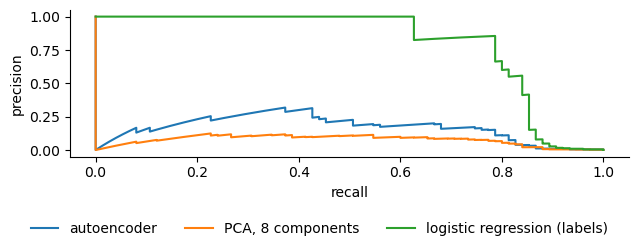

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 2.5))
for s, lab in [(err_ae, 'autoencoder'), (err_pca, 'PCA, 8 components'), (p_log, 'logistic regression (labels)')]:
    p, r, _ = precision_recall_curve(y[ite], s[ite], sample_weight=w[ite]); ax.plot(r, p, label=lab)
ax.set_xlabel('recall'); ax.set_ylabel('precision'); fig.legend(loc='lower center', ncol=3); fig.tight_layout(rect=(0, 0.12, 1, 1)); plt.show()

**Exercițiu practic:** schimbați stratul îngust `k` în `train_ae(k=...)` (2, 4, 16) și comparați PR-AUC.

## §2 Un autoencoder variațional pe Fashion-MNIST
ELBO = reconstrucție − KL; trucul reparametrizării $\mathbf z=\boldsymbol\mu+\boldsymbol\sigma\odot\boldsymbol\varepsilon$. Aici zece epoci (douăzeci în slide-uri).

In [6]:
import torchvision
root = '../data/raw/vision'
os.makedirs(root, exist_ok=True)
tr = torchvision.datasets.FashionMNIST(root, train=True, download=True)
te = torchvision.datasets.FashionMNIST(root, train=False, download=True)
Xtr, Xte = (tr.data.float() / 255).view(-1, 784), (te.data.float() / 255).view(-1, 784)
yte = te.targets.numpy()

class VAE(nn.Module):
    def __init__(self, k=2, h=400):
        super().__init__()
        self.e = nn.Sequential(nn.Linear(784, h), nn.ReLU(), nn.Linear(h, h // 2), nn.ReLU())
        self.mu, self.lv = nn.Linear(h // 2, k), nn.Linear(h // 2, k)
        self.d = nn.Sequential(nn.Linear(k, h // 2), nn.ReLU(), nn.Linear(h // 2, h), nn.ReLU(), nn.Linear(h, 784))
    def forward(self, x):
        h = self.e(x); mu, lv = self.mu(h), self.lv(h)
        z = mu + torch.exp(0.5 * lv) * torch.randn_like(mu)        # reparameterisation trick
        return self.d(z), mu, lv

def elbo_terms(logits, x, mu, lv):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction='sum') / len(x)
    kl = -0.5 * torch.sum(1 + lv - mu ** 2 - lv.exp()) / len(x)
    return rec, kl

def train_vae(k=2, beta=1.0, epochs=10, seed=1):
    torch.manual_seed(seed); m = VAE(k).to(DEVICE); opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    xt, xv = Xtr.to(DEVICE), Xte.to(DEVICE)
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(xt)).to(DEVICE)
        for b in range(0, len(perm), 128):
            x = xt[perm[b:b + 128]]; lg, mu, lv = m(x); rec, kl = elbo_terms(lg, x, mu, lv)
            opt.zero_grad(); (rec + beta * kl).backward(); opt.step()
        m.eval()
        with torch.no_grad():
            lg, mu, lv = m(xv); rec, kl = elbo_terms(lg, xv, mu, lv)
        print(f'epoch {ep + 1}: test reconstruction {float(rec):.1f}, KL {float(kl):.2f} nats')
    return m.cpu()

vae2 = train_vae(k=2)

epoch 1: test reconstruction 265.7, KL 6.33 nats


epoch 2: test reconstruction 260.6, KL 6.05 nats


epoch 3: test reconstruction 258.9, KL 6.15 nats


epoch 4: test reconstruction 256.7, KL 6.39 nats


epoch 5: test reconstruction 256.5, KL 5.85 nats


epoch 6: test reconstruction 255.3, KL 6.31 nats


epoch 7: test reconstruction 254.5, KL 6.43 nats


epoch 8: test reconstruction 254.1, KL 6.70 nats


epoch 9: test reconstruction 253.7, KL 6.29 nats


epoch 10: test reconstruction 254.1, KL 6.38 nats


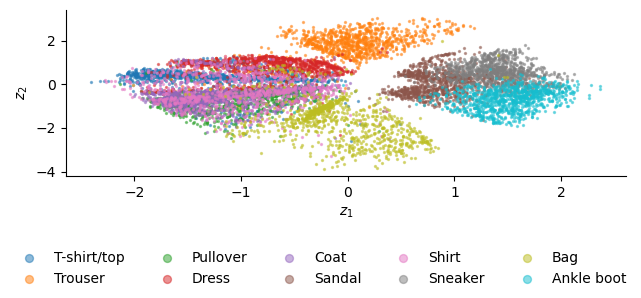

In [7]:
with torch.no_grad():
    z = vae2.mu(vae2.e(Xte)).numpy()
CL = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for c in range(10):
    ax.scatter(z[yte == c, 0], z[yte == c, 1], s=2, alpha=0.5, label=CL[c])
ax.set_xlabel('$z_1$'); ax.set_ylabel('$z_2$'); fig.legend(loc='lower center', ncol=5, markerscale=4)
fig.tight_layout(rect=(0, 0.2, 1, 1)); plt.show()

## §3 Un GAN pe randamentele zilnice S&P 500
Antrenare 2005–2019, test din 2020; valoarea la risc de 1 % din eșantioanele GAN, simularea istorică și distribuția normală.

In [8]:
from scipy import stats
x = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
px = x[x.ticker == 'SP500'].set_index('date')['adjclose'].dropna()
end = (px.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
r = np.log(px.loc[:end]).diff().dropna()
rtr, rte = r.loc[:'2019-12-31'], r.loc['2020-01-01':]
s_tr = float(rtr.std()); ztr = (rtr.values / s_tr).astype(np.float32)
torch.manual_seed(1)
G = nn.Sequential(nn.Linear(8, 64), nn.LeakyReLU(0.2), nn.Linear(64, 64), nn.LeakyReLU(0.2), nn.Linear(64, 1))
D = nn.Sequential(nn.Linear(1, 64), nn.LeakyReLU(0.2), nn.Linear(64, 64), nn.LeakyReLU(0.2), nn.Linear(64, 1))
og = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999)); od = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
xr = torch.tensor(ztr).unsqueeze(1); bce = F.binary_cross_entropy_with_logits; ones, zeros = torch.ones(256, 1), torch.zeros(256, 1)
for it in range(6000):
    real = xr[torch.randint(0, len(xr), (256,))]; fake = G(torch.randn(256, 8))
    ld = bce(D(real), ones) + bce(D(fake.detach()), zeros); od.zero_grad(); ld.backward(); od.step()
    lg = bce(D(fake), ones); og.zero_grad(); lg.backward(); og.step()          # non-saturating generator loss
with torch.no_grad():
    g = G(torch.randn(200000, 8)).numpy().ravel()
print('excess kurtosis: real', round(stats.kurtosis(ztr), 2), ' GAN', round(stats.kurtosis(g), 2))
q_gan = np.quantile(g, 0.01) * s_tr; q_hs = np.quantile(ztr, 0.01) * s_tr; q_n = stats.norm.ppf(0.01, rtr.mean(), s_tr)
for name, q in [('historical', q_hs), ('GAN', q_gan), ('Gaussian', q_n)]:
    print(f'{name:10s} 1% quantile {100 * q:.2f} %, exceedances 2020+: {100 * np.mean(rte.values < q):.2f} %')

excess kurtosis: real 11.86  GAN 6.17
historical 1% quantile -3.48 %, exceedances 2020+: 1.11 %
GAN        1% quantile -3.30 %, exceedances 2020+: 1.40 %
Gaussian   1% quantile -2.67 %, exceedances 2020+: 2.39 %


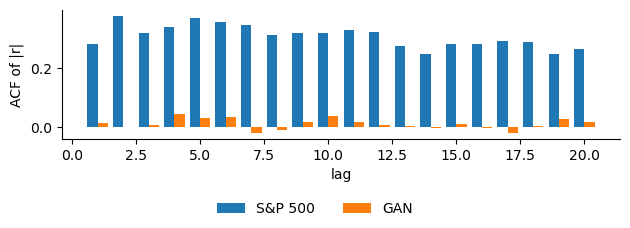

In [9]:
def acf_abs(x, lags=20):
    a = np.abs(x) - np.abs(x).mean()
    return np.array([np.sum(a[l:] * a[:-l]) / np.sum(a * a) for l in range(1, lags + 1)])
fig, ax = plt.subplots(figsize=(6.4, 2.3))
ax.bar(np.arange(1, 21) - 0.2, acf_abs(ztr), 0.4, label='S&P 500')
ax.bar(np.arange(1, 21) + 0.2, acf_abs(g[:len(ztr)]), 0.4, label='GAN')
ax.set_xlabel('lag'); ax.set_ylabel('ACF of |r|')
fig.legend(loc='lower center', ncol=2); fig.tight_layout(rect=(0, 0.12, 1, 1)); plt.show()

## §4 Un model de difuzie pentru curba randamentelor din zona euro
Procesul înainte $\mathbf x_t=\sqrt{\bar\alpha_t}\mathbf x_0+\sqrt{1-\bar\alpha_t}\boldsymbol\varepsilon$, o rețea mică prezice $\boldsymbol\varepsilon$; model de referință: o normală multivariată.

In [10]:
yc = pd.read_csv(DATA + 'ecb_yield_curve_daily.csv', parse_dates=['date']).set_index('date')
end = (yc.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
MAT = ['y_3M', 'y_6M', 'y_1Y', 'y_2Y', 'y_3Y', 'y_5Y', 'y_7Y', 'y_10Y', 'y_15Y', 'y_20Y', 'y_30Y']
Y = yc.loc[:end, MAT].dropna().values.astype(np.float32); ym, ys = Y.mean(0), Y.std(0); Yz = (Y - ym) / ys
T = 200; betas = torch.linspace(1e-4, 0.02, T); alphas = 1 - betas; abar = torch.cumprod(alphas, 0)

class Denoiser(nn.Module):
    def __init__(self, d=11, h=256, te=32):
        super().__init__(); self.te = te
        self.net = nn.Sequential(nn.Linear(d + te, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, d))
    def forward(self, x, t):
        f = torch.exp(-np.log(1000) * torch.arange(self.te // 2) / (self.te // 2)); a = t.float()[:, None] * f[None]
        return self.net(torch.cat([x, torch.sin(a), torch.cos(a)], 1))

torch.manual_seed(1); net = Denoiser(); opt = torch.optim.Adam(net.parameters(), lr=1e-3)
sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 12000); X0 = torch.tensor(Yz)
for it in range(12000):
    x0 = X0[torch.randint(0, len(X0), (512,))]; t = torch.randint(0, T, (512,)); eps = torch.randn_like(x0)
    xt = abar[t].sqrt()[:, None] * x0 + (1 - abar[t]).sqrt()[:, None] * eps
    loss = F.mse_loss(net(xt, t), eps); opt.zero_grad(); loss.backward(); opt.step(); sch.step()

@torch.no_grad()
def sample(n=5000):
    torch.manual_seed(1001); x = torch.randn(n, 11)
    for t in reversed(range(T)):
        e = net(x, torch.full((n,), t)); x = (x - betas[t] / (1 - abar[t]).sqrt() * e) / alphas[t].sqrt()
        if t > 0: x = x + betas[t].sqrt() * torch.randn_like(x)
    return x.numpy() * ys + ym

S = sample(); Gs = np.random.default_rng(20261108).multivariate_normal(np.zeros(11), np.cov(Yz.T), 5000) * ys + ym
for name, Z in [('real', Y), ('DDPM', S), ('Gaussian', Gs)]:
    print(f'{name:9s} inverted curves {100 * np.mean(Z[:, 7] < Z[:, 0]):.1f} %, negative 10Y {100 * np.mean(Z[:, 7] < 0):.1f} %')
print('Wasserstein distance of the 10Y yield: DDPM', round(stats.wasserstein_distance(Y[:, 7], S[:, 7]), 3),
      ' Gaussian', round(stats.wasserstein_distance(Y[:, 7], Gs[:, 7]), 3))

real      inverted curves 8.7 %, negative 10Y 13.8 %
DDPM      inverted curves 9.8 %, negative 10Y 9.7 %
Gaussian  inverted curves 14.2 %, negative 10Y 9.3 %
Wasserstein distance of the 10Y yield: DDPM 0.143  Gaussian 0.313


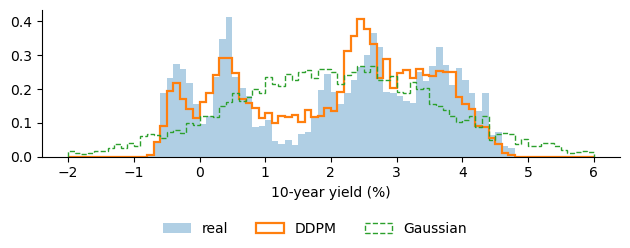

In [11]:
b = np.linspace(-2, 6, 81)
fig, ax = plt.subplots(figsize=(6.4, 2.5))
ax.hist(Y[:, 7], bins=b, density=True, alpha=0.35, label='real')
ax.hist(S[:, 7], bins=b, density=True, histtype='step', lw=1.6, label='DDPM')
ax.hist(Gs[:, 7], bins=b, density=True, histtype='step', ls='--', label='Gaussian')
ax.set_xlabel('10-year yield (%)')
fig.legend(loc='lower center', ncol=3); fig.tight_layout(rect=(0, 0.12, 1, 1)); plt.show()